# 1: IMPORTS AND CONFIGURATION¶

In [1]:
import os
import re
import time
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models

from sklearn.model_selection import train_test_split

# -------------------- CONFIGURATION --------------------

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5
VAL_SIZE = 0.15
LEARNING_RATE = 3e-4
NUM_WORKERS = 2

ROOT = Path("/kaggle/input/competitions/iic-dlp-nppe-2")

TRAIN_DIR = ROOT / "train"
TEST_DIR = ROOT / "test"
SAMPLE_PATH = ROOT / "sample_submission.csv"

OUT_DIR = Path("/kaggle/working/")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SUBMISSION_PATH = OUT_DIR / "submission.csv"
CHECKPOINT_PATH = OUT_DIR / "best_model.pth"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# -------------------- VERIFY INPUT PATHS --------------------

assert TRAIN_DIR.is_dir(), f"Missing: {TRAIN_DIR}"
assert TEST_DIR.is_dir(), f"Missing: {TEST_DIR}"
assert SAMPLE_PATH.is_file(), f"Missing: {SAMPLE_PATH}"

print("Training directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)
print("Sample submission:", SAMPLE_PATH)
print("Output directory:", OUT_DIR)

# -------------------- REPRODUCIBILITY --------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Configuration completed successfully.")


Device: cuda
GPU: Tesla T4
Training directory: /kaggle/input/competitions/iic-dlp-nppe-2/train
Test directory: /kaggle/input/competitions/iic-dlp-nppe-2/test
Sample submission: /kaggle/input/competitions/iic-dlp-nppe-2/sample_submission.csv
Output directory: /kaggle/working
Configuration completed successfully.


# 2: CLASS NAMES AND LABEL MAPPING

In [2]:
CLASS_NAMES = [
    "Apple_Apple_scab",
    "Apple_Black_rot",
    "Apple_Cedar_apple_rust",
    "Apple_healthy",
    "Blueberry_healthy",
    "Cherry_including_sour_Powdery_mildew",
    "Cherry_including_sour_healthy",
    "Corn_maize_Cercospora_leaf_spot_Gray_leaf_spot",
    "Corn_maize_Common_rust_",
    "Corn_maize_Northern_Leaf_Blight",
    "Corn_maize_healthy",
    "Grape_Black_rot",
    "Grape_Esca_Black_Measles_",
    "Grape_Leaf_blight_Isariopsis_Leaf_Spot_",
    "Grape_healthy",
    "Orange_Haunglongbing_Citrus_greening_",
    "Peach_Bacterial_spot",
    "Peach_healthy",
    "Pepper,_bell_Bacterial_spot",
    "Pepper,_bell_healthy",
    "Potato_Early_blight",
    "Potato_Late_blight",
    "Potato_healthy",
    "Raspberry_healthy",
    "Soybean_healthy",
    "Squash_Powdery_mildew",
    "Strawberry_Leaf_scorch",
    "Strawberry_healthy",
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_Septoria_leaf_spot",
    "Tomato_Spider_mites_Two-spotted_spider_mite",
    "Tomato_Target_Spot",
    "Tomato_Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato_Tomato_mosaic_virus",
    "Tomato_healthy",
]

NUM_CLASSES = len(CLASS_NAMES)

assert NUM_CLASSES == 38

def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", name.lower())

NAME_TO_LABEL = {
    normalize_name(name): label
    for label, name in enumerate(CLASS_NAMES)
}

print("Total classes:", NUM_CLASSES)

for label, class_name in enumerate(CLASS_NAMES):
    print(f"{label:2d} -> {class_name}")


Total classes: 38
 0 -> Apple_Apple_scab
 1 -> Apple_Black_rot
 2 -> Apple_Cedar_apple_rust
 3 -> Apple_healthy
 4 -> Blueberry_healthy
 5 -> Cherry_including_sour_Powdery_mildew
 6 -> Cherry_including_sour_healthy
 7 -> Corn_maize_Cercospora_leaf_spot_Gray_leaf_spot
 8 -> Corn_maize_Common_rust_
 9 -> Corn_maize_Northern_Leaf_Blight
10 -> Corn_maize_healthy
11 -> Grape_Black_rot
12 -> Grape_Esca_Black_Measles_
13 -> Grape_Leaf_blight_Isariopsis_Leaf_Spot_
14 -> Grape_healthy
15 -> Orange_Haunglongbing_Citrus_greening_
16 -> Peach_Bacterial_spot
17 -> Peach_healthy
18 -> Pepper,_bell_Bacterial_spot
19 -> Pepper,_bell_healthy
20 -> Potato_Early_blight
21 -> Potato_Late_blight
22 -> Potato_healthy
23 -> Raspberry_healthy
24 -> Soybean_healthy
25 -> Squash_Powdery_mildew
26 -> Strawberry_Leaf_scorch
27 -> Strawberry_healthy
28 -> Tomato_Bacterial_spot
29 -> Tomato_Early_blight
30 -> Tomato_Late_blight
31 -> Tomato_Leaf_Mold
32 -> Tomato_Septoria_leaf_spot
33 -> Tomato_Spider_mites_Two-spo

# 3: LOAD TRAINING IMAGE PATHS

In [3]:
print("Reading training folders...")

folder_map = {}

for folder in TRAIN_DIR.iterdir():
    if folder.is_dir():
        key = normalize_name(folder.name)

        if key in NAME_TO_LABEL:
            label = NAME_TO_LABEL[key]

            if label in folder_map:
                raise ValueError(
                    f"Duplicate class folder for label {label}"
                )

            folder_map[label] = folder

# Check whether all 38 classes exist.

missing = sorted(
    set(range(NUM_CLASSES)) - set(folder_map.keys())
)

if missing:
    raise ValueError(
        f"Missing class folders for labels: {missing}"
    )

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

train_paths = []
train_labels = []

for label in range(NUM_CLASSES):

    folder = folder_map[label]

    files = sorted([
        p for p in folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in VALID_EXTENSIONS
    ])

    train_paths.extend(str(p) for p in files)
    train_labels.extend([label] * len(files))

    print(
        f"Class {label:2d}: "
        f"{CLASS_NAMES[label]} - {len(files)} images"
    )

train_paths = np.asarray(train_paths)
train_labels = np.asarray(train_labels, dtype=np.int64)

if len(train_paths) == 0:
    raise RuntimeError("No training images found.")

print("\nTotal training images:", len(train_paths))

# Verify the class distribution.

class_counts = pd.Series(train_labels).value_counts().sort_index()

class_summary = pd.DataFrame({
    "Label": range(NUM_CLASSES),
    "Class_Name": CLASS_NAMES,
    "Image_Count": class_counts.values
})

display(class_summary)


Reading training folders...
Class  0: Apple_Apple_scab - 504 images
Class  1: Apple_Black_rot - 496 images
Class  2: Apple_Cedar_apple_rust - 220 images
Class  3: Apple_healthy - 1316 images
Class  4: Blueberry_healthy - 1201 images
Class  5: Cherry_including_sour_Powdery_mildew - 841 images
Class  6: Cherry_including_sour_healthy - 683 images
Class  7: Corn_maize_Cercospora_leaf_spot_Gray_leaf_spot - 410 images
Class  8: Corn_maize_Common_rust_ - 953 images
Class  9: Corn_maize_Northern_Leaf_Blight - 788 images
Class 10: Corn_maize_healthy - 929 images
Class 11: Grape_Black_rot - 944 images
Class 12: Grape_Esca_Black_Measles_ - 1106 images
Class 13: Grape_Leaf_blight_Isariopsis_Leaf_Spot_ - 860 images
Class 14: Grape_healthy - 338 images
Class 15: Orange_Haunglongbing_Citrus_greening_ - 4405 images
Class 16: Peach_Bacterial_spot - 1837 images
Class 17: Peach_healthy - 288 images
Class 18: Pepper,_bell_Bacterial_spot - 797 images
Class 19: Pepper,_bell_healthy - 1182 images
Class 20: P

,Label,Class_Name,Image_Count
0,0,Apple_Apple_scab,504
1,1,Apple_Black_rot,496
2,2,Apple_Cedar_apple_rust,220
3,3,Apple_healthy,1316
4,4,Blueberry_healthy,1201
5,5,Cherry_including_sour_Powdery_mildew,841
6,6,Cherry_including_sour_healthy,683
7,7,Corn_maize_Cercospora_leaf_spot_Gray_leaf_spot,410
8,8,Corn_maize_Common_rust_,953
9,9,Corn_maize_Northern_Leaf_Blight,788


# 4: TRANSFORMS, DATASET AND DATA LOADERS

In [4]:
# -------------------- TRAIN TRANSFORM --------------------

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.12,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# -------------------- VALIDATION / TEST TRANSFORM --------------------

valid_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# -------------------- DATASET CLASS --------------------

class PlantDataset(Dataset):

    def __init__(self, paths, labels=None, transform=None):
        self.paths = list(paths)
        self.labels = (
            None if labels is None else list(labels)
        )
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        with Image.open(self.paths[idx]) as img:
            img = img.convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        if self.labels is None:
            return img

        return img, int(self.labels[idx])

# -------------------- STRATIFIED SPLIT --------------------

train_idx, val_idx = train_test_split(
    np.arange(len(train_paths)),
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=train_labels
)

# Separate datasets allow different transforms.

train_base = PlantDataset(
    train_paths,
    train_labels,
    train_transform
)

val_base = PlantDataset(
    train_paths,
    train_labels,
    valid_transform
)

train_ds = Subset(train_base, train_idx)
val_ds = Subset(val_base, val_idx)

# -------------------- DATA LOADERS --------------------

pin_memory = DEVICE.type == "cuda"

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Inspect one batch.

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())


Training samples: 36914
Validation samples: 6515
Training batches: 1154
Validation batches: 204
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: [15, 34, 13, 15, 31, 15, 35, 20, 15, 24]


# 5: BUILD EFFICIENTNET-B0

In [5]:
print("Loading EfficientNet-B0...")

try:
    weights = models.EfficientNet_B0_Weights.DEFAULT

    model = models.efficientnet_b0(
        weights=weights
    )

    print("Pretrained ImageNet weights loaded.")

except Exception as e:
    print("Pretrained weights unavailable:", repr(e))
    print("Using random initialization.")

    model = models.efficientnet_b0(
        weights=None
    )

# Replace the final classification layer.

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

# Loss function.

criterion = nn.CrossEntropyLoss()

# Optimizer.

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# Learning rate scheduler.

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# Mixed precision training for CUDA.

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Model device:", DEVICE)
print("Number of output classes:", NUM_CLASSES)
print("Input features to classifier:", in_features)
print("Mixed precision enabled:", USE_AMP)

print("\nModel ready for training.")


Loading EfficientNet-B0...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 226MB/s]

Pretrained ImageNet weights loaded.
Model device: cuda
Number of output classes: 38
Input features to classifier: 1280
Mixed precision enabled: True

Model ready for training.


# 6: TRAINING AND VALIDATION

In [6]:
best_val_acc = -1.0
best_state = copy.deepcopy(model.state_dict())
history = []

for epoch in range(1, EPOCHS + 1):

    start = time.time()

    # -------------------- TRAINING --------------------

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for step, (images, labels) in enumerate(
        train_loader, start=1
    ):

        images = images.to(
            DEVICE, non_blocking=True
        )

        labels = labels.to(
            DEVICE, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)

        correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()

        total += labels.size(0)

        if step % 100 == 0:
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Batch {step}/{len(train_loader)}"
            )

    train_loss = total_loss / total
    train_acc = correct / total

    # -------------------- VALIDATION --------------------

    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                DEVICE, non_blocking=True
            )

            labels = labels.to(
                DEVICE, non_blocking=True
            )

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                logits = model(images)
                loss = criterion(logits, labels)

            val_loss_sum += (
                loss.item() * labels.size(0)
            )

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step()

    # Record metrics.

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    # Save the best model.

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_state,
            CHECKPOINT_PATH
        )

    elapsed = time.time() - start

    print(
        f"\nEpoch {epoch}/{EPOCHS} completed\n"
        f"Train Loss: {train_loss:.4f}\n"
        f"Train Accuracy: {train_acc:.4%}\n"
        f"Validation Loss: {val_loss:.4f}\n"
        f"Validation Accuracy: {val_acc:.4%}\n"
        f"Best Validation Accuracy: {best_val_acc:.4%}\n"
        f"Time: {elapsed:.1f} seconds\n"
    )

# Restore the best checkpoint.

model.load_state_dict(best_state)
model.eval()

# Save training history.

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUT_DIR / "training_history.csv",
    index=False
)

print("Training completed.")
print(f"Best validation accuracy: {best_val_acc:.4%}")
print("Checkpoint:", CHECKPOINT_PATH)

display(history_df)


Epoch 1/5 | Batch 100/1154
Epoch 1/5 | Batch 200/1154
Epoch 1/5 | Batch 300/1154
Epoch 1/5 | Batch 400/1154
Epoch 1/5 | Batch 500/1154
Epoch 1/5 | Batch 600/1154
Epoch 1/5 | Batch 700/1154
Epoch 1/5 | Batch 800/1154
Epoch 1/5 | Batch 900/1154
Epoch 1/5 | Batch 1000/1154
Epoch 1/5 | Batch 1100/1154

Epoch 1/5 completed
Train Loss: 0.2713
Train Accuracy: 92.8591%
Validation Loss: 0.0407
Validation Accuracy: 98.7260%
Best Validation Accuracy: 98.7260%
Time: 334.3 seconds

Epoch 2/5 | Batch 100/1154
Epoch 2/5 | Batch 200/1154
Epoch 2/5 | Batch 300/1154
Epoch 2/5 | Batch 400/1154
Epoch 2/5 | Batch 500/1154
Epoch 2/5 | Batch 600/1154
Epoch 2/5 | Batch 700/1154
Epoch 2/5 | Batch 800/1154
Epoch 2/5 | Batch 900/1154
Epoch 2/5 | Batch 1000/1154
Epoch 2/5 | Batch 1100/1154

Epoch 2/5 completed
Train Loss: 0.0607
Train Accuracy: 98.1172%
Validation Loss: 0.0209
Validation Accuracy: 99.2786%
Best Validation Accuracy: 99.2786%
Time: 227.3 seconds

Epoch 3/5 | Batch 100/1154
Epoch 3/5 | Batch 200/115

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.271302,0.928591,0.040654,0.987260
1,2,0.060707,0.981172,0.020885,0.992786
2,3,0.033105,0.989218,0.012227,0.996470
3,4,0.017991,0.994555,0.007261,0.998158
4,5,0.011002,0.996478,0.007372,0.997851


# PLOT TRAINING HISTORY

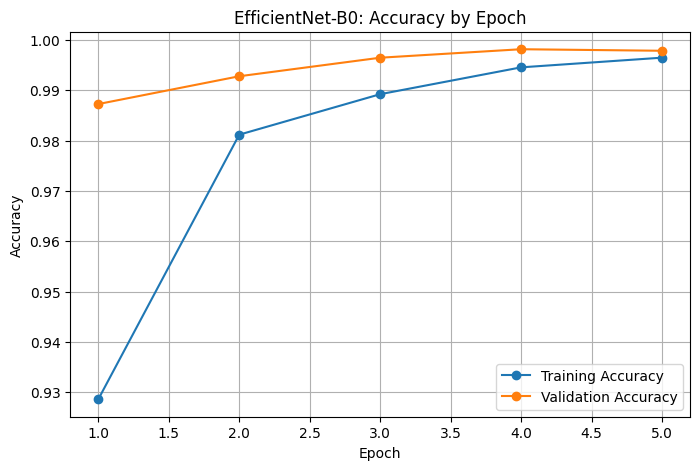

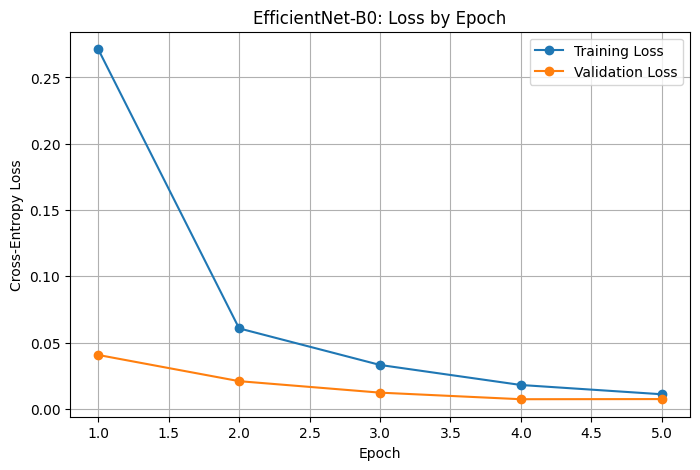

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0: Accuracy by Epoch")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("EfficientNet-B0: Loss by Epoch")
plt.legend()
plt.grid(True)
plt.show()


# 7: LOAD TEST IMAGES

In [8]:
print("Reading test filenames...")

sample = pd.read_csv(SAMPLE_PATH)

required_columns = {"Image_ID", "Label"}

if not required_columns.issubset(sample.columns):
    raise ValueError(
        f"Sample submission must contain: {required_columns}"
    )

test_files = {}

for p in TEST_DIR.iterdir():

    if (
        p.is_file()
        and p.suffix.lower() in VALID_EXTENSIONS
    ):

        if p.stem in test_files:
            raise ValueError(
                f"Duplicate test image ID: {p.stem}"
            )

        test_files[p.stem] = p

# Read IDs in the exact sample submission order.

image_ids = sample["Image_ID"].astype(str).tolist()

missing_ids = [
    image_id
    for image_id in image_ids
    if image_id not in test_files
]

if missing_ids:
    raise FileNotFoundError(
        f"{len(missing_ids)} sample IDs were not found. "
        f"Examples: {missing_ids[:10]}"
    )

test_paths = [
    str(test_files[image_id])
    for image_id in image_ids
]

test_ds = PlantDataset(
    test_paths,
    labels=None,
    transform=valid_transform
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

print("Total test images:", len(test_ds))
print("Test batches:", len(test_loader))
print("First 5 image IDs:", image_ids[:5])


Reading test filenames...
Total test images: 10876
Test batches: 340
First 5 image IDs: ['image_00001', 'image_00002', 'image_00003', 'image_00004', 'image_00005']


# 8: GENERATE TEST PREDICTIONS

In [9]:
model.eval()

predictions = []

with torch.no_grad():

    for batch_num, images in enumerate(
        test_loader, start=1
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            logits = model(images)

        batch_predictions = (
            logits.argmax(dim=1)
            .cpu()
            .numpy()
            .tolist()
        )

        predictions.extend(batch_predictions)

        if batch_num % 50 == 0:
            completed = min(
                batch_num * BATCH_SIZE,
                len(test_ds)
            )

            print(
                f"Predicted {completed}/{len(test_ds)} images"
            )

predictions = np.asarray(
    predictions,
    dtype=np.int64
)

assert len(predictions) == len(sample)

assert predictions.min() >= 0
assert predictions.max() < NUM_CLASSES

print("Prediction completed.")
print("Number of predictions:", len(predictions))
print("First 10 predicted labels:", predictions[:10])


Predicted 1600/10876 images
Predicted 3200/10876 images
Predicted 4800/10876 images
Predicted 6400/10876 images
Predicted 8000/10876 images
Predicted 9600/10876 images
Prediction completed.
Number of predictions: 10876
First 10 predicted labels: [0 0 0 0 0 0 0 0 0 0]


# 9: CREATE FINAL SUBMISSION

In [10]:
submission = pd.DataFrame({
    "Image_ID": image_ids,
    "Label": predictions
})

# Validate submission format.

assert list(submission.columns) == [
    "Image_ID", "Label"
]

assert len(submission) == len(sample)

assert submission["Image_ID"].equals(
    sample["Image_ID"].astype(str)
)

assert submission["Label"].notna().all()

assert submission["Label"].between(
    0, NUM_CLASSES - 1
).all()

# Save the submission.

submission.to_csv(
    SUBMISSION_PATH,
    index=False
)

# Read it back to verify the saved file.

saved_submission = pd.read_csv(
    SUBMISSION_PATH
)

assert len(saved_submission) == len(sample)

assert list(saved_submission.columns) == [
    "Image_ID", "Label"
]

print("\nSUBMISSION CREATED SUCCESSFULLY!")
print("File:", SUBMISSION_PATH)
print("Number of rows:", len(submission))

print("\nFirst 10 predictions:")
display(submission.head(10))

print("\nPredicted label distribution:")
display(
    submission["Label"]
    .value_counts()
    .sort_index()
    .rename_axis("Label")
    .reset_index(name="Count")
)

print("\nSaved files:")

for file in sorted(OUT_DIR.iterdir()):
    print(
        file.name,
        f"({file.stat().st_size / (1024 ** 2):.2f} MB)"
    )

print(
    "\nOpen the Kaggle notebook Output section "
    "to locate submission.csv."
)



SUBMISSION CREATED SUCCESSFULLY!
File: /kaggle/working/submission.csv
Number of rows: 10876

First 10 predictions:


,Image_ID,Label
0,image_00001,0
1,image_00002,0
2,image_00003,0
3,image_00004,0
4,image_00005,0
5,image_00006,0
6,image_00007,0
7,image_00008,0
8,image_00009,0
9,image_00010,0



Predicted label distribution:


,Label,Count
0,0,126
1,1,125
2,2,55
3,3,329
4,4,301
5,5,211
6,6,169
7,7,99
8,8,239
9,9,201



Saved files:
__notebook__.ipynb (0.16 MB)
best_model.pth (15.76 MB)
submission.csv (0.15 MB)
training_history.csv (0.00 MB)

Open the Kaggle notebook Output section to locate submission.csv.
